In [84]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import os, sys
import numpy as np
import pandas as pd
from itertools import chain
from functools import reduce
from copy import deepcopy
from itertools import product, combinations

from rdkit import Chem
from rdkit.Chem import PandasTools, AllChem
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addStereoAnnotation = False

from new_geass import Geass
sys.path.append(R'C:\Users\Idener\Sync\CODE')
from CADDTools import molecular_methods as MolMtd

def flatten(list):
    flat_list = [item for sublist in list for item in sublist]
    return(flat_list)
clear_output(wait=False)

In [85]:
database3 = pd.read_csv('data/Database3.csv')
PandasTools.AddMoleculeColumnToFrame(database3, smilesCol='ISOSMILES')

df_lotus = pd.read_pickle('data/Database_LOTUS.pkl')

,ID,ISOSMILES,Formula,ROMol
148736,LTS0186939,CC(C)=CCC[C@](O)(CO[C@H]1O[C@H](CO)[C@@H](O)[C...,C53H88O22,

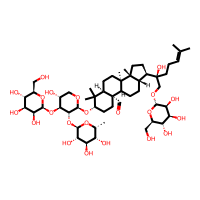

In [86]:
sample = df_lotus.sample(1)
#! Check: BS_0754, LTS0262572
# sample = database3[database3['ID'] == 'LTS0262572']

mol = sample['ROMol'].iloc[0]
display(sample)

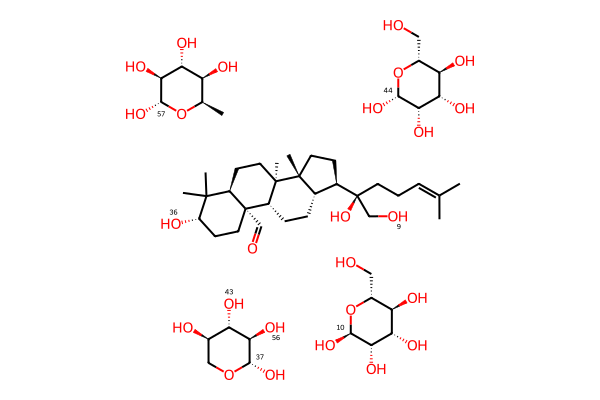

In [87]:
geass = Geass(mol)
geass.get_bonds_to_break()
final_prods = geass.get_fragments()

final_Prod = reduce(Chem.CombineMols, final_prods)
MolMtd.show_atom_indices(MolMtd.reset_view(final_Prod), prop='old_mapno')

In [89]:
geass.show_connections_graph()

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…